# TP1 PROCESAMIENTO DEL HABLA

**Mariela Malizia.**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


### Entrega de los ejercicios

1. Crea un repositorio GitHub público dedicado a esta materia.
2. Sube tus notebooks de resolución para cada desafío allí.
3. Por cada desafío utilizaremos un sólo notebook.
4. Debes entregar tu TP1 en el foro correspondiente, siguiendo las instrucciones que allí indica.




## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Para este trabajo seleccioné una entrevista a Gabriel Rolón publicada en el sitio Aprendemos Juntos 2030 de BBVA. Elegí este material porque aborda temáticas vinculadas con los vínculos, el amor y las experiencias humanas, relacionadas con mi campo de interés.

El objetivo de esta primera etapa es extraer el contenido textual de una única página web mediante web scraping para utilizarlo posteriormente en las tareas de preprocesamiento y análisis solicitadas.

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


In [16]:
import requests
from bs4 import BeautifulSoup

In [17]:
url = "https://aprendemosjuntos.bbva.com/especial/en-un-mundo-en-blanco-y-negro-los-que-amamos-nos-llenan-de-color-gabriel-rolon/"

respuesta = requests.get(url)

print(respuesta.status_code)

200


In [18]:
soup = BeautifulSoup(respuesta.text, "html.parser")

print(soup.title)

<title>Â¿CÃ³mo dar sentido a tu vida? - Gabriel RolÃ³n - BBVA Aprendemos Juntos</title>


In [19]:
respuesta.encoding = "utf-8"

soup = BeautifulSoup(respuesta.text, "html.parser")

print(soup.title.get_text())

¿Cómo dar sentido a tu vida? - Gabriel Rolón - BBVA Aprendemos Juntos


In [20]:
parrafos = soup.find_all("p")

print("Cantidad de párrafos encontrados:", len(parrafos))

for parrafo in parrafos:
    print(parrafo.get_text(strip=True))

Cantidad de párrafos encontrados: 51
Gabriel Rolón es un reconocido psicoanalista y escritor cuya trayectoria está marcada por la curiosidad y la habilidad innata para conectar con las experiencias cotidianas de las personas. Su travesía académica no solo fue un proceso de “aprendizajes y fracasos”, sino también una búsqueda constante para encontrarse consigo mismo y ser quien realmente es.
Su carisma y capacidad para comunicar temas psicológicos de manera clara le convierten en un referente en la divulgación psicológica, llevando la introspección a millones de hogares e inspirando a las personas a reflexionar sobre sus propias vidas. El psicoanalista sostiene que nos encontramos en la era de la incomunicación y el desencuentro, e insiste en “comunicarnos de verdad y usar palabras que nos representen”.
Como autor y apasionado del arte, Rolón ha plasmado sus conocimientos y experiencias en libros, teatro y diferentes medios audiovisuales. Obras como ‘Palabras cruzadas’, ‘Historias de di

In [21]:
texto = " ".join(parrafo.get_text(strip=True) for parrafo in parrafos)

print(texto[:2000])

Gabriel Rolón es un reconocido psicoanalista y escritor cuya trayectoria está marcada por la curiosidad y la habilidad innata para conectar con las experiencias cotidianas de las personas. Su travesía académica no solo fue un proceso de “aprendizajes y fracasos”, sino también una búsqueda constante para encontrarse consigo mismo y ser quien realmente es. Su carisma y capacidad para comunicar temas psicológicos de manera clara le convierten en un referente en la divulgación psicológica, llevando la introspección a millones de hogares e inspirando a las personas a reflexionar sobre sus propias vidas. El psicoanalista sostiene que nos encontramos en la era de la incomunicación y el desencuentro, e insiste en “comunicarnos de verdad y usar palabras que nos representen”. Como autor y apasionado del arte, Rolón ha plasmado sus conocimientos y experiencias en libros, teatro y diferentes medios audiovisuales. Obras como ‘Palabras cruzadas’, ‘Historias de diván y ‘Los padecientes’ entre otros, 

Resultado del web scraping

Para realizar el web scraping utilicé las bibliotecas requests y BeautifulSoup, siguiendo la técnica trabajada en clase. Primero se realizó la solicitud a la página web seleccionada y se verificó que respondiera correctamente mediante el código de estado 200. Luego se utilizó BeautifulSoup para interpretar el contenido HTML.

Se buscaron las etiquetas , correspondientes a los párrafos de la página, y se obtuvieron 51 párrafos. Finalmente, estos párrafos se unieron en una única variable llamada texto, que será utilizada en las siguientes etapas del trabajo.

Fuente del procedimiento: código adaptado a partir de los ejemplos de web scraping proporcionados por la cátedra.

Fuente del código: procedimiento basado en los ejemplos de web scraping proporcionados por la cátedra y adaptado a la página seleccionada. Para la adaptación y organización del código se utilizó asistencia de ChatGPT (OpenAI).

## 2- Preprocesamiento

### 2.1 Muestra las stop words que tenga tu texto.

In [22]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Descargar los recursos necesarios de NLTK
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [23]:
# Tokenizamos el texto: lo separamos en palabras
tokens = word_tokenize(texto.lower(), language="spanish")

# Cargamos las stopwords del idioma español
stopwords_es = set(stopwords.words("spanish"))

# Buscamos cuáles de esas stopwords aparecen en nuestro texto
stopwords_en_texto = sorted(set(
    palabra for palabra in tokens
    if palabra in stopwords_es
))

print("Stopwords encontradas en el texto:")
print(stopwords_en_texto)

print("\nCantidad de stopwords diferentes:", len(stopwords_en_texto))

Stopwords encontradas en el texto:
['a', 'al', 'algo', 'algunas', 'algunos', 'antes', 'como', 'con', 'contra', 'cual', 'cuando', 'de', 'del', 'desde', 'donde', 'durante', 'e', 'el', 'ella', 'ellas', 'ellos', 'en', 'entre', 'era', 'eran', 'eres', 'es', 'esa', 'esas', 'ese', 'eso', 'esos', 'esta', 'estaba', 'estaban', 'estabas', 'estado', 'estados', 'estamos', 'estando', 'estar', 'estas', 'este', 'esto', 'estos', 'estoy', 'estuve', 'estuviera', 'estuvimos', 'estuvo', 'está', 'están', 'estás', 'fue', 'fuera', 'fueron', 'fui', 'ha', 'habrá', 'había', 'habíamos', 'habían', 'han', 'hasta', 'hay', 'haya', 'hayamos', 'he', 'hemos', 'hubiera', 'hubieras', 'hubiéramos', 'hubo', 'la', 'las', 'le', 'les', 'lo', 'los', 'me', 'mi', 'mis', 'mucho', 'muchos', 'muy', 'más', 'mí', 'mío', 'míos', 'nada', 'ni', 'no', 'nos', 'nosotros', 'nuestra', 'nuestras', 'nuestros', 'o', 'os', 'otra', 'otras', 'otro', 'otros', 'para', 'pero', 'poco', 'por', 'porque', 'que', 'quien', 'qué', 'se', 'sea', 'sean', 'sentid

Stopwords encontradas

Se tokenizó el texto, es decir, se lo dividió en palabras, y se utilizó la lista de stopwords en español de la biblioteca NLTK. Luego se identificaron las stopwords presentes en el texto extraído.

Se encontraron 160 stopwords diferentes. Estas son palabras de uso muy frecuente, como artículos, preposiciones y pronombres, que generalmente aportan poca información para identificar los temas principales del texto.

Fuente del código: procedimiento basado en los materiales de la cátedra sobre limpieza y preprocesamiento de texto con NLTK. El código fue adaptado al texto seleccionado con asistencia de ChatGPT (OpenAI).

### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

In [24]:
import re

# Pasamos el texto a minúsculas
texto_limpio = texto.lower()

# Eliminamos caracteres extraños y signos
texto_limpio = re.sub(r'[^\w\s]', ' ', texto_limpio)

# Separamos el texto en palabras
palabras = texto_limpio.split()

# Eliminamos las stopwords
palabras_limpias = [
    palabra for palabra in palabras
    if palabra not in stopwords_es
]

# Volvemos a unir las palabras para formar el texto limpio
texto_limpio = " ".join(palabras_limpias)

print(texto_limpio[:2000])

gabriel rolón reconocido psicoanalista escritor cuya trayectoria marcada curiosidad habilidad innata conectar experiencias cotidianas personas travesía académica solo proceso aprendizajes fracasos sino búsqueda constante encontrarse consigo mismo ser realmente carisma capacidad comunicar temas psicológicos manera clara convierten referente divulgación psicológica llevando introspección millones hogares inspirando personas reflexionar propias vidas psicoanalista sostiene encontramos incomunicación desencuentro insiste comunicarnos verdad usar palabras representen autor apasionado arte rolón plasmado conocimientos experiencias libros teatro diferentes medios audiovisuales obras palabras cruzadas historias diván padecientes testimonios pericia combinar profundidad psicoanálisis narrativas cautivadoras motivadas deseo compartir historias llenas vida siempre dispuse tiempo robado diagnósticos aprovecharlo cosas quisiera jugar deseos reales hacer fácil papá albañil trabajaba obrero construcc

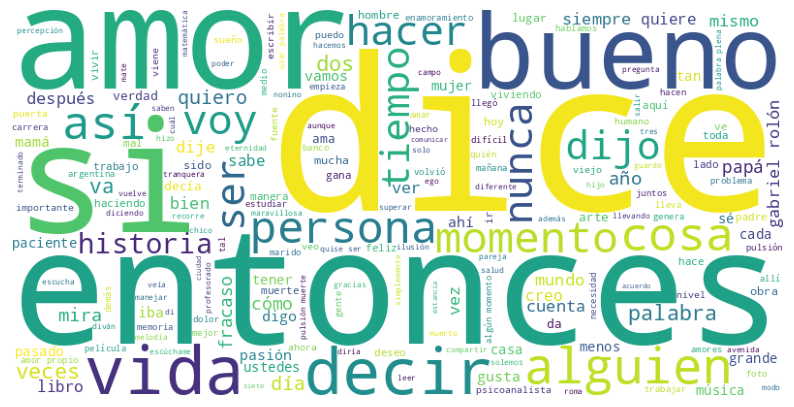

In [25]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Creamos la nube de palabras con el texto limpio
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(texto_limpio)

# Mostramos la nube
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

Interpretación de la nube de palabras

La nube permite visualizar las palabras que aparecen con mayor frecuencia en el texto luego de eliminar las stopwords y los caracteres extraños. Se destacan términos vinculados con el contenido de la entrevista, como “amor”, “vida”, “persona”, “tiempo” e “historia”.

También aparecen con alta frecuencia palabras como “entonces”, “dice”, “dijo” y “bueno”, que son características del lenguaje oral y narrativo de la entrevista, pero no necesariamente representan sus temas principales. Esto muestra que la frecuencia de aparición de una palabra por sí sola no siempre permite determinar su relevancia dentro del contenido.

Fuente del código: código adaptado del ejemplo de uso de WordCloud incluido por la cátedra en el notebook del TP1. Se reemplazó el texto de ejemplo por el texto obtenido y preprocesado de la página seleccionada.

### 2.3 Usando el texto que conseguiste en el punto 1).



#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [26]:
from nltk.tokenize import sent_tokenize

# Dividimos el texto original en oraciones
oraciones = sent_tokenize(texto, language="spanish")

print("Cantidad de oraciones:", len(oraciones))

# Mostramos las primeras 5 para comprobar el resultado
for oracion in oraciones[:5]:
    print(oracion)

Cantidad de oraciones: 508
Gabriel Rolón es un reconocido psicoanalista y escritor cuya trayectoria está marcada por la curiosidad y la habilidad innata para conectar con las experiencias cotidianas de las personas.
Su travesía académica no solo fue un proceso de “aprendizajes y fracasos”, sino también una búsqueda constante para encontrarse consigo mismo y ser quien realmente es.
Su carisma y capacidad para comunicar temas psicológicos de manera clara le convierten en un referente en la divulgación psicológica, llevando la introspección a millones de hogares e inspirando a las personas a reflexionar sobre sus propias vidas.
El psicoanalista sostiene que nos encontramos en la era de la incomunicación y el desencuentro, e insiste en “comunicarnos de verdad y usar palabras que nos representen”.
Como autor y apasionado del arte, Rolón ha plasmado sus conocimientos y experiencias en libros, teatro y diferentes medios audiovisuales.


In [27]:
from sklearn.feature_extraction.text import CountVectorizer

# Creamos el vectorizador
vectorizador = CountVectorizer(
    stop_words=list(stopwords_es)
)

# Construimos la matriz documento-vocabulario
matriz_documento_vocabulario = vectorizador.fit_transform(oraciones)

# Obtenemos las palabras que forman el vocabulario
vocabulario = vectorizador.get_feature_names_out()

print("Tamaño de la matriz:", matriz_documento_vocabulario.shape)

Tamaño de la matriz: (508, 1539)



#### 2.3.2 Determina la longitud de tu vocabulario.

Matriz documento-vocabulario

Para representar numéricamente el texto, se consideró cada oración como un documento. El texto quedó dividido en 508 oraciones. Mediante CountVectorizer se construyó una matriz documento-vocabulario basada en la frecuencia de aparición de los términos.

La matriz obtenida tiene un tamaño de (508, 1539). Las 508 filas representan las oraciones o documentos y las 1539 columnas representan los términos diferentes que forman el vocabulario. Esta representación corresponde al enfoque Bag of Words, en el cual se considera la frecuencia de las palabras, sin tener en cuenta el orden en que aparecen.

In [28]:
# Calculamos la cantidad de términos diferentes del vocabulario
longitud_vocabulario = len(vocabulario)

print("Longitud del vocabulario:", longitud_vocabulario)

Longitud del vocabulario: 1539


Longitud del vocabulario

La longitud del vocabulario obtenido es de 1539 términos diferentes. Este valor coincide con la cantidad de columnas de la matriz documento-vocabulario, ya que cada columna representa un término del vocabulario.


#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Creamos el vectorizador TF-IDF
vectorizador_tfidf = TfidfVectorizer(
    stop_words=list(stopwords_es)
)

# Aplicamos TF-IDF a las mismas oraciones
matriz_tfidf = vectorizador_tfidf.fit_transform(oraciones)

# Obtenemos el vocabulario
vocabulario_tfidf = vectorizador_tfidf.get_feature_names_out()

print("Tamaño de la matriz TF-IDF:", matriz_tfidf.shape)

Tamaño de la matriz TF-IDF: (508, 1539)


In [30]:
import pandas as pd

# Calculamos el peso TF-IDF promedio de cada término
promedios_tfidf = matriz_tfidf.mean(axis=0).A1

# Organizamos los resultados en una tabla
resultados_tfidf = pd.DataFrame({
    "Palabra": vocabulario_tfidf,
    "TF-IDF promedio": promedios_tfidf
})

# Ordenamos de mayor a menor y mostramos los primeros 15 términos
resultados_tfidf = resultados_tfidf.sort_values(
    by="TF-IDF promedio",
    ascending=False
)

resultados_tfidf.head(15)

,Palabra,TF-IDF promedio
442,dice,0.023262
571,entonces,0.021386
81,amor,0.021249
168,bueno,0.020186
1310,si,0.016751
385,decir,0.016448
1487,vida,0.013232
121,así,0.012540
1524,voy,0.012328
56,alguien,0.012255


Interpretación de TF-IDF

La matriz TF-IDF obtenida tiene un tamaño de (508, 1539): las 508 filas corresponden a las oraciones consideradas como documentos y las 1539 columnas a los términos del vocabulario.

A diferencia de la matriz de frecuencias, TF-IDF asigna un peso a los términos teniendo en cuenta su presencia en cada documento en relación con el conjunto de documentos. Entre los términos con mayor peso promedio aparecen “amor” y “vida”, relacionados con la temática de la entrevista.

También se observan términos como “dice”, “entonces”, “bueno”, “decir”, “dijo” y “dije”, vinculados con el carácter oral y narrativo del material analizado. Esto permite observar que el preprocesamiento realizado conserva todavía expresiones frecuentes propias del discurso oral que podrían ser consideradas en una etapa posterior de limpieza.

Fuente del código: procedimiento basado en los materiales de la cátedra sobre vectorización de texto, Bag of Words y TF-IDF. El código fue adaptado al texto seleccionado con asistencia de ChatGPT (OpenAI).

# Conclusiones

Agregue aquí sus conclusiones sobre este trabajo práctico. Puede ser también parte del texto que posteará en el foro.

Conclusiones

En este trabajo realicé el proceso de extracción y análisis de un texto obtenido de una página web. Mediante web scraping se extrajeron 51 párrafos de una entrevista a Gabriel Rolón y posteriormente se realizó el preprocesamiento del contenido.

La limpieza permitió identificar y eliminar stopwords y caracteres que no resultaban relevantes para el análisis. La nube de palabras permitió realizar una primera aproximación visual a los términos más frecuentes, entre los que se destacaron palabras como “amor”, “vida” y “persona”, junto con otras expresiones características del lenguaje oral.

Posteriormente, el texto fue dividido en 508 oraciones, consideradas como documentos, y se obtuvo un vocabulario de 1539 términos. La matriz documento-vocabulario permitió transformar el contenido textual en una representación numérica de 508 × 1539.

Finalmente, mediante TF-IDF se ponderó la relevancia de los términos en los documentos. Los resultados mostraron nuevamente la presencia destacada de términos como “amor” y “vida”, aunque también conservaron expresiones propias del discurso oral. Esto permite considerar que una limpieza más específica podría mejorar futuros análisis.

Este trabajo me permitió comprender de manera práctica el recorrido que va desde la obtención de un texto en Internet hasta su transformación en datos que pueden ser analizados. Una de las principales dificultades fue comprender inicialmente el significado de la vectorización y de la matriz documento-vocabulario. Al realizar el proceso paso a paso pude comprender que vectorizar consiste en representar numéricamente el lenguaje para poder procesarlo y analizarlo.

# ENTREGA




# Anexo, código de ejemplo del uso de wordcloud

Instalar e importar la librería

In [31]:
# instalar wordcloud
!pip install wordcloud


In [32]:

# Importar librerías
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [33]:

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)


Mostramos la imagen generada

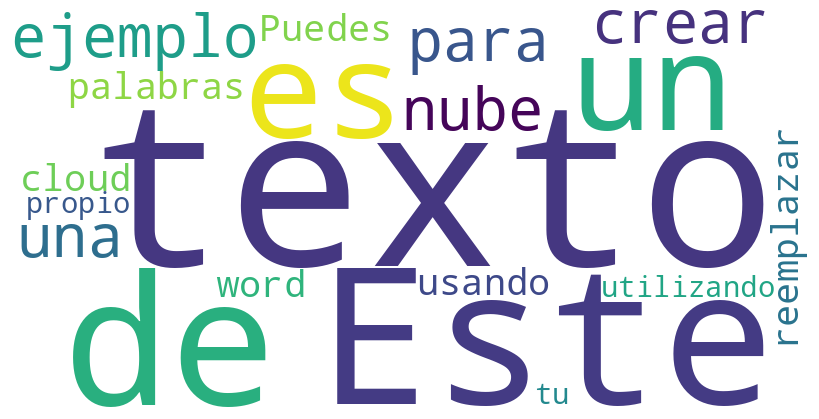

In [34]:

# mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

Modificamos el ejemplo anterior agregando palabras en español que no queremos que considere para crear la nube de palabras. Estas son las stop_words



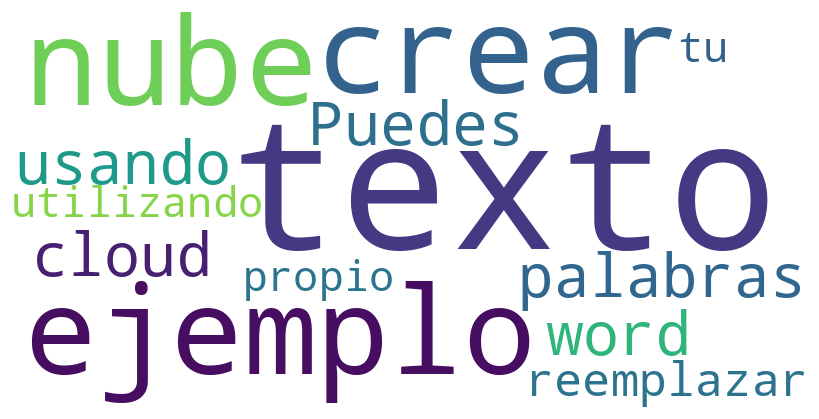

In [35]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Definir stopwords en español
stopwords_es = set(STOPWORDS)
stopwords_es.update(["con", "que", "los", "para", "un", "una", "el", "la", "en", "y", "o", "de", "a", "se", "es", "al", "como", "por", "no", "su", "más", "pero", "si", "este", "esta", "eso", "esa", "todo", "todos", "todas", "cada", "cual", "cualquier", "algo", "alguna", "algún", "ningún", "ninguna", "ninguno", "otro", "otros", "otras", "sobre", "entre", "durante", "desde", "hasta", "también", "así", "mismo", "misma", "mismo", "misma", "tan", "tanto", "tanta", "muy", "poco", "poca", "poco", "nada", "solo", "sola", "solo", "sola", "siempre", "nunca", "jamás", "casi", "aproximadamente", "cerca", "lejos", "antes", "después", "ahora", "hoy", "ayer", "mañana", "luego", "mientras", "mientras tanto", "después de", "antes de", "durante", "sin", "aunque", "a pesar de", "debido a", "gracias a", "por qué", "cómo", "dónde", "cuándo", "quién", "qué", "cuál"])

# Crear un objeto WordCloud con stopwords en español
wordcloud = WordCloud(width=800, height=400, background_color="white", stopwords=stopwords_es).generate(text)

# Mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()
